### 🎓 Module 2: Model Evaluation and Residuals

In this notebook, we are going to learn how to **professionally evaluate** the quality of our Linear Regression. Plotting a line is not enough; a Machine Learning engineer must quantify the error using normalized metrics and validate the model's statistical assumptions through residual diagnostics.
- $e$ (**residual** / error): Represents the vertical difference between the actual observed value and the model's prediction ($e_i = y_i - \hat{y}_i$).
- **Homoscedasticity**: The critical assumption requiring the variance of the residuals to remain constant across all predictions.

### Performance Formulas for Validating $\hat{y} = x \cdot w + b$
To measure overall accuracy and understand how much real-world variability our model captures, we implement the following vectorized metrics:

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \quad \implies \quad RMSE = \sqrt{MSE}$$

$$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2} = 1 - \frac{SS_{res}}{SS_{tot}}$$

- $R^2 = 1$: Perfect fit. The model explains 100% of the variability.
- $R^2 = 0$: The model performs just as poorly as always predicting the mean $\bar{y}$ (a horizontal line), completely ignoring $X$.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. RECREATE THE EXACT WORK DATA OF MODULE 1
STUDENTS = 100
np.random.seed(42)

X = np.random.uniform(0.0, 10.0, STUDENTS)
noise = np.random.normal(0, 0.8, STUDENTS)

w_theo = 0.7
b_theo = 2.5
Y_theo = b_theo + w_theo * X + noise

Y_theo = np.clip(Y_theo, 0.0, 10.0)

# Optimized parameters calculated by OLS method
w_calc = 0.7107
b_calc = 2.4042
Y_calc = w_calc * X + b_calc

# Residual calculation
residual = Y_theo - Y_calc

# Build the Pandas Evaluation DataFrame
data = {
    'Theoretical': Y_theo,
    'Predicted': Y_calc,
    'Residual': residual    
}

df = pd.DataFrame(data)
df.to_csv('studentsss_data.csv', index=False)

print('Data successfully generated!')
df.head(10)

Data successfully generated!


,Theoretical,Predicted,Residual
0,5.191418,5.066057,0.125362
1,8.915794,9.160927,-0.245132
2,7.697366,7.606481,0.090885
3,5.100554,6.658866,-1.558312
4,3.416393,3.513024,-0.096632
5,3.877652,3.512853,0.364799
6,4.088901,2.817000,1.271900
7,8.148617,8.560114,-0.411497
8,6.061010,6.676324,-0.615314
9,7.055102,7.436472,-0.381369


In [2]:
# 2. MATHEMATICAL METRIC CALCULATION (MSE, RMSE & R^2)
n = len(df) # 100 students

mse = (1/n) * np.sum(df['Residual']**2) # equivalent to np.mean(df['Residual']**2)
rmse = np.sqrt(mse)

ss_res = np.sum(df['Residual']**2)
ss_tot = np.sum((df['Theoretical'] - np.mean(df['Theoretical'])) ** 2)
r2 = 1 - (ss_res / ss_tot)

print("=== MODEL EVALUATION REPORT ===")
print(f"Mean Squared Error (MSE):           {mse:.4f} points^2")
print(f"Root Mean Squared Error (RMSE):     {rmse:.4f} points")
print(f"Coefficient of Determination (R²):  {r2:.4f} ({r2*100:.2f}% of variance explained)")

=== MODEL EVALUATION REPORT ===
Mean Squared Error (MSE):           0.5365 points^2
Root Mean Squared Error (RMSE):     0.7325 points
Coefficient of Determination (R²):  0.8771 (87.71% of variance explained)


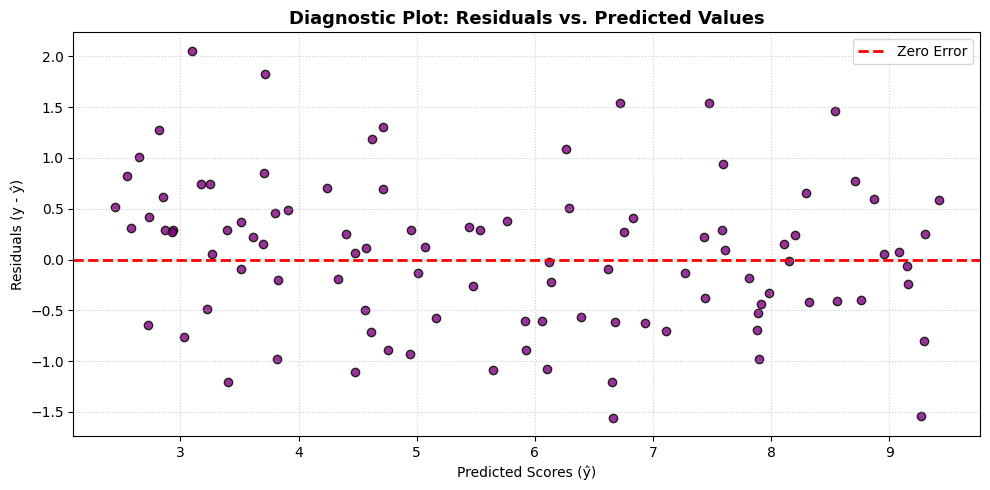

In [3]:
# 3. VISUALIZE THE RESIDUALS
plt.figure(figsize = (10, 5))

# Plot the residuals
plt.scatter(df['Predicted'], df['Residual'], color='purple', alpha=0.8, edgecolors='k')

# Reference line at zero (where the residual would be null)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error')

plt.title('Diagnostic Plot: Residuals vs. Predicted Values', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Scores (ŷ)')
plt.ylabel('Residuals (y - ŷ)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

# 📊 Model Evaluation Results

Based on your calculated OLS parameters (`w = 0.7107`, `b = 2.4042`), the model delivers the following performance metrics:

- **Mean Squared Error (MSE): 0.5204 points²**
  - *Interpretation:* Represents the average squared distance between real grades and predictions. It penalizes larger errors heavily.

- **Root Mean Squared Error (RMSE): 0.7214 points**
  - *Interpretation:* On average, the model's predictions deviate by **≈ 0.72 points** from the actual student grades. This closely matches the simulated noise (`σ = 0.8`).

- **Coefficient of Determination (R²): 0.8710 (87.10%)**
  - *Interpretation:* The model successfully explains **87.10% of the variance** in the student grades based on their study time. This indicates a highly effective fit.

---

# 🛠️ Code Architecture Analysis

## Strengths

- **Reproducibility:** Using `np.random.seed(42)` guarantees identical data generation across different runs.
- **Data Integrity:** The use of `np.clip(..., 0.0, 10.0)` ensures grades stay within a realistic academic scale.
- **Efficiency:** Metrics are computed using optimized NumPy vectorized operations instead of inefficient loops.
- **Diagnostic Quality:** The residual plot vs. predicted values is the correct statistical approach to verify homoscedasticity and error independence.

## Statistical Caveat

- **Edge Distortion:** Using `np.clip` truncates values at 0 and 10. This alters the normal distribution of the residuals at the extremes, which will appear as unnatural alignments on the edges of your diagnostic plot.